# 01 · Create the Dataset
**AI Supply Chain Optimizer — Clustering & HMM review · Component 1: problem identification & dataset selection**

| Unit folder | Notebook | What it does | Reads | Creates |
|---|---|---|---|---|
| Unit_1_2_PBL1_Data_and_Regression | **01_Create_Dataset** (this one) | loads the Kaggle data, cleans it, keeps food, removes the IPL effect, builds features | `data/` | `dataset/`, `results/01_dataset/` |
| Unit_3_PBL2_Clustering_KMeans | 02_Clustering_KMeans | groups the 58 dark stores | `dataset/` | `results/02_clustering/` |
| Unit_4_PBL2_HMM | 03_HMM | finds hidden daily demand regimes | `dataset/` | `results/03_hmm/` |
| Unit_4_PBL2_HMM | 04_Comparison_and_Results | compares K-Means and the HMM, final results | `dataset/`, Unit 3 and 4 results | `results/04_comparison/` |
| Unit_1_2_PBL1_Data_and_Regression | 05_PBL1_Regression | store-week dataset, Linear / Ridge / Bayesian regression | `dataset/` | `dataset/store_weekly.csv`, `results/05_regression/` |
| Unit_5_PBL3_Gradient_Boosting | 06_PBL3_Gradient_Boosting | gradient boosting, compared with PBL 1 | `dataset/`, `results/05_regression/` | `results/06_boosting/` |

Each notebook saves its results inside its own unit folder (`<unit folder>/results/...`); `data/` and `dataset/` are shared and sit in the project folder.

Run the notebooks in this order. *Numbers use the Indian format (1,13,390); dates are DD-MM-YYYY.*

In [1]:
# ---- Only on Google Colab (skip on your own computer) ----
# !pip install -q hmmlearn
# from google.colab import drive; drive.mount("/content/drive")
# %cd /content/drive/MyDrive/QuickCommerce_ML_Project_Final

import os, json, time, warnings, logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap

# project root = the folder that contains data/ and dataset/ (works from the unit folder, the root or Colab)
if not os.path.isdir("data") and os.path.isdir(os.path.join("..", "data")):
    os.chdir("..")
print("Working folder:", os.getcwd())

warnings.filterwarnings("ignore")
logging.getLogger("hmmlearn").setLevel(logging.ERROR)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
SEED = 42
DATE = "%d-%m-%Y"

def inr(x):
    # Indian digit grouping: 113390 -> 1,13,390
    s = f"{abs(x):.0f}"; head, tail = s[:-3], s[-3:]; parts = []
    while len(head) > 2:
        parts.insert(0, head[-2:]); head = head[:-2]
    if head: parts.insert(0, head)
    return ("-" if x < 0 else "") + ",".join(parts + [tail])

# chart style — colour-blind-safe palette in fixed order
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": MUTED,
    "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 9.5, "font.size": 8.5, "axes.labelsize": 8.5,
    "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "legend.fontsize": 7.5,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": INK2, "ytick.color": INK2,
    "lines.linewidth": 1.5, "figure.dpi": 110, "legend.frameon": False,
})

OUT = "dataset"                      # every file this notebook creates goes here
os.makedirs(OUT, exist_ok=True)
def save_fig(fig, name):
    fig.savefig(f"{OUT}/{name}.png", dpi=240, bbox_inches="tight")
    plt.show()

Working folder: /home/claude/project


In [2]:
os.makedirs("Unit_1_2_PBL1_Data_and_Regression/results/01_dataset", exist_ok=True)
FIG = "Unit_1_2_PBL1_Data_and_Regression/results/01_dataset"          # charts of this notebook go here (data files go to dataset/)
def save_chart(fig, name):
    fig.savefig(f"{FIG}/{name}.png", dpi=240, bbox_inches="tight")
    plt.show()

## 1.1 Problem statement
Quick-commerce apps (Blinkit, Zepto, Swiggy Instamart) deliver groceries in about 10 minutes from small city
warehouses called **dark stores**. Each dark store must hold the right food stock and the right number of riders.
Two questions decide this:

1. **Which dark stores behave alike?** Stores that sell the same mix of food at the same times of day can share one
   stocking and staffing plan → **Clustering** (notebook 02).
2. **What demand situation is the network in today, and what comes next?** Demand moves between hidden situations —
   normal days, monsoon days when deliveries are delayed, and festival peaks. They are not labelled in the data and must
   be inferred from what we observe each day → **Hidden Markov Model** (notebook 03).

## 1.2 Objectives
- Group the 58 dark stores into segments with similar food-demand profiles (K-Means) and explain each segment.
- Discover the hidden daily demand regimes, their switching probabilities, and decode the regime of every day (HMM).
- Compare the two methods using real experimental results.

## 1.3 Application domain
Retail supply chain / quick-commerce operations: inventory placement, safety stock, rider staffing and festival
preparation — part of the **AI Supply Chain Optimizer** (warehouse → shop distribution).

## 1.4 The dataset
**India Quick Commerce Orders 2025–2026** — Kaggle:
https://www.kaggle.com/datasets/abirambharathisa/india-quick-commerce-orders-2025-2026
(author: Abiram Bharathi S.A., licence CC0 Public Domain).

- One file, `india_quick_commerce_orders.csv` (put it in the `data/` folder) — one row per customer order.
- **Synthetic data:** the author generated it with a Python simulation of Indian city demand, weather, festivals,
  dark-store load, rider travel and stock-outs, using real festival dates. The business, customers, riders and stores
  are fictional; patterns are realistic but simplified.

In [3]:
DATA_FILE = "data/india_quick_commerce_orders.csv"
if not os.path.exists(DATA_FILE) and os.path.exists(DATA_FILE.replace(".csv", ".zip")):
    import zipfile
    zipfile.ZipFile(DATA_FILE.replace(".csv", ".zip")).extractall("data")
raw = pd.read_csv(DATA_FILE, parse_dates=["order_datetime", "order_date"])
print(f"Records: {inr(len(raw))} orders × {raw.shape[1]} columns")
print(f"Period : {raw.order_date.min():{DATE}} to {raw.order_date.max():{DATE}} ({raw.order_date.nunique()} days)")
print(f"Cities : {raw.city.nunique()}  |  dark stores: {raw.store_id.nunique()}  |  customers: {inr(raw.customer_id.nunique())}"
      f"  |  riders: {inr(raw.rider_id.nunique())}")
raw.head()

Records: 1,95,148 orders × 39 columns
Period : 01-01-2025 to 30-09-2026 (638 days)
Cities : 12  |  dark stores: 58  |  customers: 46,804  |  riders: 1,450


,order_id,order_datetime,order_date,order_hour,day_of_week,city,store_id,area_type,customer_id,is_first_order,is_member,event,weather,temperature_c,items_count,n_categories,primary_category,basket_categories,has_fresh_items,items_out_of_stock,payment_method,item_total,discount,delivery_fee,handling_fee,small_cart_fee,surge_fee,rider_tip,refund_out_of_stock,total_paid,distance_km,promised_minutes,actual_delivery_minutes,is_late,rider_id,order_status,cancel_reason,complaint_type,customer_rating
0,QC50000001,2025-01-01 00:02:00,2025-01-01,0,Wednesday,Delhi NCR,DS019,Residential,CU011436,True,False,New Year's Day,Clear,15.900,5,3,Snacks & Beverages,Snacks & Beverages; Instant & Frozen Food; Ice...,False,0,UPI,413.000,51.000,0.000,4.000,0.000,15.000,0.000,0.000,381.000,0.940,10,5.700,0.000,R019-16,Delivered,NaN,NaN,NaN
1,QC50000002,2025-01-01 00:06:00,2025-01-01,0,Wednesday,Delhi NCR,DS019,Residential,CU008185,True,False,New Year's Day,Clear,15.900,3,3,Personal Care,Snacks & Beverages; Instant & Frozen Food; Per...,False,0,Credit/Debit Card,276.000,22.000,0.000,4.000,0.000,15.000,0.000,0.000,273.000,0.630,10,6.100,0.000,R019-05,Delivered,NaN,NaN,NaN
2,QC50000003,2025-01-01 00:21:00,2025-01-01,0,Wednesday,Delhi NCR,DS021,Student / PG Hub,CU051172,True,False,New Year's Day,Clear,15.900,5,4,Pharma & Wellness,"Dairy, Bread & Eggs; Instant & Frozen Food; Ho...",True,0,Wallet,569.000,62.000,0.000,4.000,0.000,15.000,0.000,0.000,526.000,2.140,15,14.700,0.000,R021-07,Delivered,NaN,NaN,NaN
3,QC50000004,2025-01-01 01:25:00,2025-01-01,1,Wednesday,Delhi NCR,DS019,Residential,CU023847,True,False,New Year's Day,Clear,15.900,2,2,Instant & Frozen Food,Snacks & Beverages; Instant & Frozen Food,False,1,UPI,198.000,13.000,25.000,4.000,0.000,15.000,0.000,99.000,130.000,2.730,15,16.700,1.000,R019-07,Delivered (partial),NaN,NaN,4.000
4,QC50000005,2025-01-01 01:48:00,2025-01-01,1,Wednesday,Delhi NCR,DS020,Student / PG Hub,CU046319,True,False,New Year's Day,Clear,15.900,5,3,Snacks & Beverages,Snacks & Beverages; Instant & Frozen Food; Per...,False,0,UPI,459.000,33.000,0.000,4.000,0.000,15.000,0.000,0.000,445.000,1.470,10,10.000,0.000,R020-05,Delivered,NaN,NaN,NaN


## 1.5 Attributes (39 columns)

In [4]:
groups = {
    "Order & time": ["order_id", "order_datetime", "order_date", "order_hour", "day_of_week"],
    "Location": ["city", "store_id", "area_type", "distance_km"],
    "Customer": ["customer_id", "is_first_order", "is_member", "customer_rating"],
    "Context": ["event", "weather", "temperature_c"],
    "Basket": ["items_count", "n_categories", "primary_category", "basket_categories", "has_fresh_items", "items_out_of_stock"],
    "Money (₹)": ["item_total", "discount", "delivery_fee", "handling_fee", "small_cart_fee", "surge_fee",
                  "rider_tip", "refund_out_of_stock", "total_paid", "payment_method"],
    "Delivery & outcome": ["promised_minutes", "actual_delivery_minutes", "is_late", "rider_id",
                           "order_status", "cancel_reason", "complaint_type"],
}
attr = pd.DataFrame([{"group": g, "column": c, "dtype": str(raw[c].dtype), "missing": int(raw[c].isna().sum()),
                      "unique": raw[c].nunique(), "example": raw[c].dropna().iloc[0]} for g, cols in groups.items() for c in cols])
attr.to_csv("dataset/data_dictionary.csv", index=False)
print("All 39 columns covered:", len(attr) == raw.shape[1], "-> saved dataset/data_dictionary.csv")
attr

All 39 columns covered: True -> saved dataset/data_dictionary.csv


,group,column,dtype,missing,unique,example
0,Order & time,order_id,str,0,195148,QC50000001
1,Order & time,order_datetime,datetime64[us],0,166334,2025-01-01 00:02:00
2,Order & time,order_date,datetime64[us],0,638,2025-01-01 00:00:00
3,Order & time,order_hour,int64,0,24,0
4,Order & time,day_of_week,str,0,7,Wednesday
5,Location,city,str,0,12,Delhi NCR
6,Location,store_id,str,0,58,DS019
7,Location,area_type,str,0,4,Residential
8,Location,distance_km,float64,0,621,0.940
9,Customer,customer_id,str,0,46804,CU011436


## 1.6 Exploration — summary statistics

In [5]:
num = ["item_total", "discount", "total_paid", "items_count", "distance_km", "actual_delivery_minutes", "customer_rating"]
display(raw[num].describe().T)
pd.DataFrame({c: [raw[c].nunique(), raw[c].value_counts().index[0], f"{raw[c].value_counts(normalize=True).iloc[0]:.1%}"]
              for c in ["city", "area_type", "event", "weather", "primary_category", "payment_method", "order_status"]},
             index=["categories", "most common", "share"]).T

,count,mean,std,min,25%,50%,75%,max
item_total,"195,148.000",530.433,326.505,23.000,298.000,463.000,688.000,"3,961.000"
discount,"195,148.000",39.036,36.813,0.000,14.000,29.000,53.000,567.000
total_paid,"195,148.000",490.365,299.191,0.000,276.000,429.000,635.000,"3,838.000"
items_count,"195,148.000",4.566,1.934,1.000,3.000,4.000,6.000,16.000
distance_km,"195,148.000",1.723,1.123,0.300,0.880,1.480,2.300,6.500
actual_delivery_minutes,"192,005.000",11.126,5.152,4.000,7.500,10.100,13.600,57.700
customer_rating,"72,944.000",4.343,0.696,1.000,4.000,4.000,5.000,5.000


,categories,most common,share
city,12,Delhi NCR,21.6%
area_type,4,Residential,55.8%
event,9,Regular day,75.4%
weather,4,Clear,68.9%
primary_category,14,"Atta, Rice & Dal",14.1%
payment_method,5,UPI,73.8%
order_status,3,Delivered,85.6%


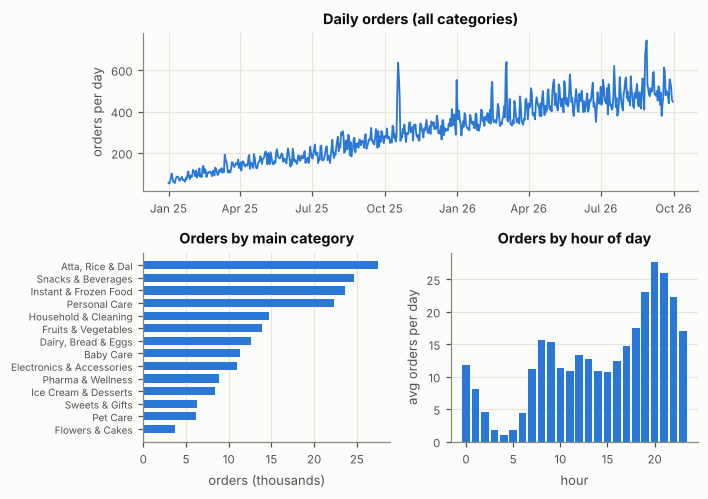

In [6]:
fig = plt.figure(figsize=(6.5, 4.6)); gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.2])
axes = [fig.add_subplot(gs[0, :]), fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])]
d_all = raw.groupby("order_date").size()
axes[0].plot(d_all.index, d_all.values, color=BLUE, lw=1.2)
axes[0].set(title="Daily orders (all categories)", ylabel="orders per day")
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
pc = raw.primary_category.value_counts().sort_values()
axes[1].barh(pc.index, pc.values / 1e3, color=BLUE, height=0.65)
axes[1].set(title="Orders by main category", xlabel="orders (thousands)"); axes[1].grid(axis="y", visible=False)
axes[1].tick_params(axis="y", labelsize=6.5)
hr = raw.groupby("order_hour").size() / raw.order_date.nunique()
axes[2].bar(hr.index, hr.values, color=BLUE, width=0.8)
axes[2].set(title="Orders by hour of day", xlabel="hour", ylabel="avg orders per day"); axes[2].grid(axis="x", visible=False)
plt.tight_layout(); save_chart(fig, "eda_overview")

## 1.7 Preprocessing
### (a) Data-quality checks

In [7]:
calc = (raw.item_total - raw.discount - raw.refund_out_of_stock + raw.delivery_fee + raw.handling_fee
        + raw.small_cart_fee + raw.surge_fee + raw.rider_tip)
formula_ok = np.isclose(calc, raw.total_paid, atol=1)
print(f"Duplicate order IDs / rows      : {raw.order_id.duplicated().sum()} / {raw.duplicated().sum()}")
print(f"total_paid matches its formula   : {formula_ok.mean():.1%}  — the rest are {raw.loc[~formula_ok, 'order_status'].unique().tolist()} orders (nothing paid)")
print(f"Negative amounts                 : {(raw[['item_total', 'discount', 'total_paid']] < 0).sum().sum()}")
missing = raw.isna().sum(); missing = missing[missing > 0]
pd.DataFrame({"missing": missing, "share": (missing / len(raw)).map("{:.1%}".format),
              "reason": ["cancelled orders were never delivered", "cancelled orders were never delivered",
                         "only filled when the order was cancelled", "only filled when there was a complaint",
                         "customer did not rate the order"]})

Duplicate order IDs / rows      : 0 / 0
total_paid matches its formula   : 98.4%  — the rest are ['Cancelled'] orders (nothing paid)
Negative amounts                 : 0


,missing,share,reason
actual_delivery_minutes,3143,1.6%,cancelled orders were never delivered
is_late,3143,1.6%,cancelled orders were never delivered
cancel_reason,192005,98.4%,only filled when the order was cancelled
complaint_type,185367,95.0%,only filled when there was a complaint
customer_rating,122204,62.6%,customer did not rate the order


Missing values are **structural, not errors** — they are kept as missing and never filled with invented numbers.

### (b) Keep food categories only
The project is about food distribution. Each order is classified by its **main category** (`primary_category`);
orders whose main category is non-food (personal care, household, baby care, electronics, pharma, pet care, flowers)
are removed. To change the categories, edit the `FOOD` list below.

In [8]:
FOOD = ["Fruits & Vegetables", "Snacks & Beverages", "Instant & Frozen Food", "Dairy, Bread & Eggs",
        "Atta, Rice & Dal", "Ice Cream & Desserts", "Sweets & Gifts"]
keep = raw.primary_category.isin(FOOD)
print("Removed (non-food main category):"); print(raw.loc[~keep, "primary_category"].value_counts().to_string())
food = raw[keep].copy()
print(f"\nFood orders kept: {inr(len(food))} of {inr(len(raw))} ({len(food)/len(raw):.1%})")

Removed (non-food main category):
primary_category
Personal Care                22380
Household & Cleaning         14750
Baby Care                    11293
Electronics & Accessories    10922
Pharma & Wellness             8840
Pet Care                      6182
Flowers & Cakes               3704

Food orders kept: 1,17,077 of 1,95,148 (60.0%)


### (c) Remove the IPL effect
128 days are IPL match days. On those days the data has extra evening orders (7–11 pm) caused by cricket viewing;
daytime demand is unchanged. To keep IPL out of the analysis:
1. measure, for every store, its normal ratio of evening to daytime orders on regular days of the IPL season (March–May);
2. compute how many evening orders the store would have had on IPL days at that normal ratio;
3. drop each IPL-evening order with the store's excess probability (unbiased, `seed = 42`);
4. relabel IPL match days as regular days.

In [9]:
food["evening"] = food.order_hour.between(19, 22)
food["month"] = food.order_date.dt.month
is_ipl = food.event.eq("IPL match day")
IPL_DATES = sorted(food.loc[is_ipl, "order_date"].unique())

sd = (food.groupby(["store_id", "order_date"])
          .agg(evening=("evening", "sum"), total=("order_id", "size"), event=("event", "first"), month=("month", "first"))
          .reset_index())
sd["daytime"] = sd.total - sd.evening
season = sd[sd.month.isin([3, 4, 5]) & sd.event.isin(["Regular day", "IPL match day"])]
print("Average orders per store-day in March–May:")
display(season.assign(day_type=np.where(season.event.eq("IPL match day"), "IPL match day", "regular day"))
              .groupby("day_type")[["daytime", "evening"]].mean().round(2))

reg = season[season.event.eq("Regular day")]
normal_ratio = reg.groupby("store_id").evening.sum() / reg.groupby("store_id").daytime.sum()
ipl_store = sd[sd.event.eq("IPL match day")].groupby("store_id")[["evening", "daytime"]].sum()
ipl_store["expected_evening"] = ipl_store.daytime * ipl_store.index.map(normal_ratio).fillna(reg.evening.sum() / reg.daytime.sum())
ipl_store["p_remove"] = ((ipl_store.evening - ipl_store.expected_evening) / ipl_store.evening).clip(0, 1)

rng = np.random.default_rng(SEED)
candidates = food[is_ipl & food.evening]
drop = candidates.order_id[rng.random(len(candidates)) < candidates.store_id.map(ipl_store.p_remove).values]
clean = food[~food.order_id.isin(drop)].copy()
clean["was_ipl_day"] = clean.order_date.isin(IPL_DATES)
clean.loc[clean.event.eq("IPL match day"), "event"] = "Regular day"
print(f"IPL match days: {len(IPL_DATES)} ({pd.Timestamp(IPL_DATES[0]):{DATE}} to {pd.Timestamp(IPL_DATES[-1]):{DATE}})")
print(f"Extra IPL-evening orders removed: {inr(len(drop))}  ->  clean food orders: {inr(len(clean))}")
ipl_store.round(3).to_csv("dataset/ipl_removal_by_store.csv")

Average orders per store-day in March–May:


,daytime,evening
day_type,,
IPL match day,2.590,1.810
regular day,2.550,1.100


IPL match days: 128 (22-03-2025 to 31-05-2026)
Extra IPL-evening orders removed: 3,687  ->  clean food orders: 1,13,390


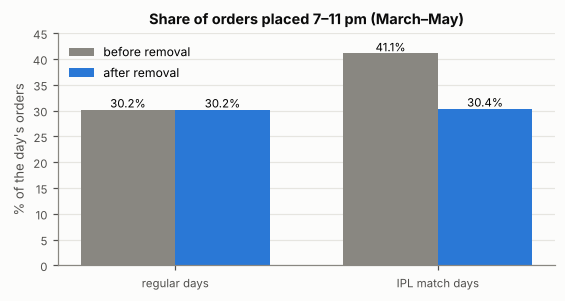

In [10]:
def evening_share(df):
    s = df[df.month.isin([3, 4, 5])]
    return s.groupby(np.where(s.order_date.isin(IPL_DATES), "IPL match days", "regular days")).evening.mean() * 100
before, after = evening_share(food), evening_share(clean)
fig, ax = plt.subplots(figsize=(5.2, 2.8))
xpos = np.arange(2); w = 0.36
vb = [before["regular days"], before["IPL match days"]]; va = [after["regular days"], after["IPL match days"]]
ax.bar(xpos - w/2, vb, w, color=MUTED, label="before removal")
ax.bar(xpos + w/2, va, w, color=BLUE, label="after removal")
for i in range(2):
    ax.text(i - w/2, vb[i] + 0.4, f"{vb[i]:.1f}%", ha="center", fontsize=7.5); ax.text(i + w/2, va[i] + 0.4, f"{va[i]:.1f}%", ha="center", fontsize=7.5)
ax.set_xticks(xpos); ax.set_xticklabels(["regular days", "IPL match days"])
ax.set(title="Share of orders placed 7–11 pm (March–May)", ylabel="% of the day's orders", ylim=(0, 45))
ax.grid(axis="x", visible=False); ax.legend(fontsize=8)
plt.tight_layout(); save_chart(fig, "ipl_removal")

### (d) Feature construction
- **Store table** (for clustering) — one row per dark store: demand level and demand profile (time of day,
  food-category mix, basket value) plus service indicators.
- **Daily table** (for the HMM) — one row per day for the whole network:
  - **demand index** = log(orders ÷ expected orders), expected = 29-day rolling median × the usual weekday factor.
    It removes the growth of the business (about 6×) and the weekend effect, so only *unusual* demand remains
    (0 = normal day, +0.3 ≈ 35% above normal);
  - **late-delivery rate** = share of delivered orders that arrived after the promised time.

In [11]:
clean["stockout"] = clean.items_out_of_stock > 0
clean["complaint"] = clean.complaint_type.notna()
clean["cancelled"] = clean.order_status.eq("Cancelled")
clean["night"] = clean.order_hour.isin([22, 23, 0, 1, 2, 3, 4, 5])
clean["morning"] = clean.order_hour.between(6, 9)
g = clean.groupby("store_id")
days_open = g.order_date.agg(lambda s: (s.max() - s.min()).days + 1)
stores = pd.DataFrame({
    "city": g.city.first(), "area_type": g.area_type.first(), "first_order": g.order_date.min(), "days_open": days_open,
    "orders_per_day": g.size() / days_open, "avg_basket_value": g.item_total.mean(), "avg_items": g.items_count.mean(),
    "discount_pct": g.discount.sum() / g.item_total.sum() * 100, "night_share": g.night.mean() * 100,
    "morning_share": g.morning.mean() * 100, "late_rate": g.is_late.mean() * 100,
    "avg_delivery_min": g.actual_delivery_minutes.mean(), "avg_distance_km": g.distance_km.mean(),
    "stockout_rate": g.stockout.mean() * 100, "cancel_rate": g.cancelled.mean() * 100,
    "complaint_rate": g.complaint.mean() * 100, "member_share": g.is_member.mean() * 100,
})
SHORT = {"Fruits & Vegetables": "fruit_veg", "Snacks & Beverages": "snacks_bev", "Instant & Frozen Food": "instant_frozen",
         "Dairy, Bread & Eggs": "dairy_bread_eggs", "Atta, Rice & Dal": "atta_rice_dal", "Ice Cream & Desserts": "icecream_desserts",
         "Sweets & Gifts": "sweets"}
for cat, short in SHORT.items():
    stores["share_" + short] = clean.basket_categories.str.contains(cat, regex=False).groupby(clean.store_id).mean() * 100
print(f"Store table: {stores.shape[0]} dark stores × {stores.shape[1]} columns")
stores.head()

Store table: 58 dark stores × 24 columns


,city,area_type,first_order,days_open,orders_per_day,avg_basket_value,avg_items,discount_pct,night_share,morning_share,late_rate,avg_delivery_min,avg_distance_km,stockout_rate,cancel_rate,complaint_rate,member_share,share_fruit_veg,share_snacks_bev,share_instant_frozen,share_dairy_bread_eggs,share_atta_rice_dal,share_icecream_desserts,share_sweets
store_id,,,,,,,,,,,,,,,,,,,,,,,,
DS001,Bengaluru,Student / PG Hub,2025-01-01,638,5.122,449.922,4.491,7.782,37.362,9.608,27.767,11.302,1.749,13.494,1.591,5.171,18.727,40.606,69.400,47.368,49.969,27.020,28.550,5.630
DS002,Bengaluru,Residential,2025-01-01,638,3.397,446.142,4.461,7.772,23.950,18.182,28.898,11.285,1.730,12.137,1.154,5.122,17.120,48.408,61.375,43.609,57.176,29.303,21.735,5.630
DS003,Bengaluru,Premium Residential,2025-01-01,638,3.150,452.856,4.489,7.726,25.224,17.413,29.838,11.353,1.741,11.592,1.791,5.970,16.766,47.363,62.289,43.234,56.219,30.000,22.090,6.020
DS004,Bengaluru,Premium Residential,2025-01-01,638,6.282,441.708,4.465,7.743,23.328,18.089,28.593,11.262,1.706,12.799,1.572,5.289,17.839,47.779,61.053,41.866,58.757,29.466,22.954,5.639
DS005,Bengaluru,Residential,2025-09-08,388,4.575,451.546,4.496,7.033,23.887,17.239,28.982,11.165,1.741,13.296,2.028,4.958,18.592,46.873,63.549,42.761,57.014,30.028,20.958,5.634


Weekday factors (orders vs a typical day): {'Friday': '0.95', 'Monday': '0.96', 'Saturday': '1.12', 'Sunday': '1.12', 'Thursday': '0.96', 'Tuesday': '0.93', 'Wednesday': '0.96'}
Daily table: 638 days


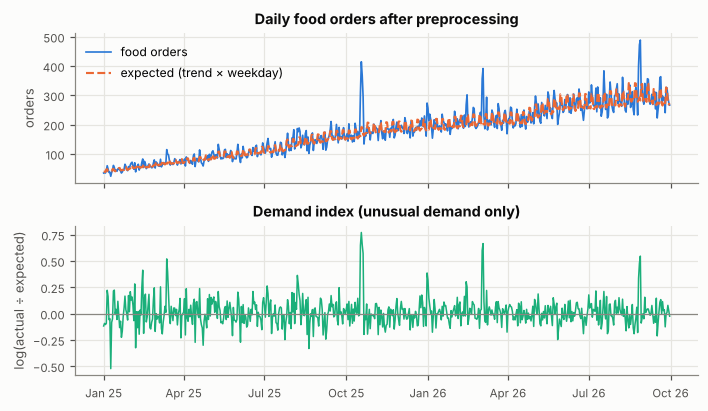

In [12]:
daily = clean.groupby("order_date").agg(orders=("order_id", "size"), event=("event", "first"),
                                        dow=("day_of_week", "first"), late_rate=("is_late", "mean"),
                                        rain_share=("weather", lambda s: s.isin(["Rain", "Heavy Rain"]).mean()))
daily["trend"] = daily.orders.rolling(29, center=True, min_periods=8).median()
log_ratio = np.log(daily.orders / daily.trend)
weekday_factor = log_ratio[daily.event.eq("Regular day")].groupby(daily.dow).median()
daily["expected"] = daily.trend * np.exp(daily.dow.map(weekday_factor))
daily["demand_index"] = np.log(daily.orders / daily.expected)
print("Weekday factors (orders vs a typical day):", {k: f"{np.exp(v):.2f}" for k, v in weekday_factor.items()})
print(f"Daily table: {len(daily)} days")

fig, axes = plt.subplots(2, 1, figsize=(6.5, 3.8), sharex=True)
axes[0].plot(daily.index, daily.orders, color=BLUE, lw=1.1, label="food orders")
axes[0].plot(daily.index, daily.expected, color=ORANGE, lw=1.4, ls="--", label="expected (trend × weekday)")
axes[0].set(title="Daily food orders after preprocessing", ylabel="orders"); axes[0].legend(fontsize=8)
axes[1].plot(daily.index, daily.demand_index, color=AQUA, lw=1.0)
axes[1].axhline(0, color=MUTED, lw=0.8)
axes[1].set(title="Demand index (unusual demand only)", ylabel="log(actual ÷ expected)")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
plt.tight_layout(); save_chart(fig, "daily_demand_index")

## 1.8 Save the dataset files

In [13]:
ORIGINAL = list(raw.columns)
clean[ORIGINAL + ["was_ipl_day"]].to_csv("dataset/clean_food_orders.csv", index=False)
stores.to_csv("dataset/store_features.csv")
daily.to_csv("dataset/daily_series.csv")
for f in sorted(os.listdir("dataset")):
    print(f"dataset/{f:28s} {os.path.getsize('dataset/' + f) / 1e6:7.2f} MB")

dataset/clean_food_orders.csv          35.79 MB
dataset/daily_series.csv                0.07 MB
dataset/data_dictionary.csv             0.00 MB
dataset/ipl_removal_by_store.csv        0.00 MB
dataset/store_features.csv              0.02 MB
dataset/store_weekly.csv                0.21 MB


| File | Rows | What it contains | Used by |
|---|---|---|---|
| `dataset/clean_food_orders.csv` | 1,13,390 orders | food orders after cleaning and IPL removal (original 39 columns + `was_ipl_day`) | 02, 04 |
| `dataset/store_features.csv` | 58 stores | demand profile and service indicators of every dark store | 02 |
| `dataset/daily_series.csv` | 638 days | orders, expected orders, demand index, late rate, rain share, event | 03 |
| `dataset/data_dictionary.csv` | 39 columns | column groups, types, missing values | — |
| `dataset/ipl_removal_by_store.csv` | 58 stores | IPL evening orders, expected orders and removal probability | — |

## 1.9 Suitability of the dataset
- **Indian quick-commerce structure:** 12 Indian cities, 58 dark stores, Indian festivals, monsoon, UPI payments,
  food from fresh produce to packaged snacks.
- **Rich enough for clustering:** 58 stores in distinct locations (residential, student/PG hubs, offices).
- **Long enough for an HMM:** 638 consecutive days in which hidden regimes (normal / monsoon / festival) switch.
- **Limitation:** synthetic and simplified — results show the *method*; numbers are not real business figures.

## Readings used in the report
Every number quoted in the report (Chapter 3 – Sections 3.2 to 3.4) that is not already shown above is printed here, computed from this notebook's own results.

In [14]:
print("Table 3.3 – missing values in the raw dataset")
for label, col in [("actual_delivery_minutes, is_late", "actual_delivery_minutes"), ("cancel_reason", "cancel_reason"),
                   ("complaint_type", "complaint_type"), ("customer_rating", "customer_rating")]:
    n = raw[col].isna().sum()
    print(f"  {label:36s} {inr(n):>9s} ({n / len(raw):.1%})")
print(f"\nFood filter: kept {inr(len(food))} of {inr(len(raw))} orders ({len(food) / len(raw):.1%}); "
      f"non-food orders removed: {inr(len(raw) - len(food))}")
print(f"IPL removal: {inr(len(food) - len(clean))} orders removed, {inr(len(clean))} clean food orders")
print("\nShare of orders placed 7–11 pm, March–May (%)  [Figure 3.1 / Section 3.3]")
print(f"  IPL match days : before removal {before['IPL match days']:.1f}  ->  after removal {after['IPL match days']:.1f}")
print(f"  regular days   : {after['regular days']:.1f}")
first, last = d_all.iloc[:30].mean(), d_all.iloc[-30:].mean()
print(f"\nDaily orders, all categories [Figure 3.2]: first 30 days {first:.0f} per day, last 30 days {last:.0f} per day")

Table 3.3 – missing values in the raw dataset
  actual_delivery_minutes, is_late         3,143 (1.6%)
  cancel_reason                         1,92,005 (98.4%)
  complaint_type                        1,85,367 (95.0%)
  customer_rating                       1,22,204 (62.6%)

Food filter: kept 1,17,077 of 1,95,148 orders (60.0%); non-food orders removed: 78,071
IPL removal: 3,687 orders removed, 1,13,390 clean food orders

Share of orders placed 7–11 pm, March–May (%)  [Figure 3.1 / Section 3.3]
  IPL match days : before removal 41.1  ->  after removal 30.4
  regular days   : 30.2

Daily orders, all categories [Figure 3.2]: first 30 days 76 per day, last 30 days 497 per day
